<a href="https://colab.research.google.com/github/guruprasathr1996-cyber/Spam_Detection_System/blob/main/SMS_Spam_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import numpy as np
import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from google.colab import files
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

tf.keras.utils.set_random_seed(42)

print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.21.0


In [3]:

#uploaded = files.upload()

df = pd.read_csv("spam.csv", encoding="latin-1")

# Select the required columns
df = df[["v1", "v2"]]
df.columns = ["label", "message"]

print("Original dataset shape:", df.shape)
print(df.head())


Original dataset shape: (5572, 2)
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


In [4]:

df = df.dropna(subset=["label", "message"])
df = df.drop_duplicates(subset=["message"])
df = df[df["label"].isin(["ham", "spam"])].copy()

# Convert labels to numeric values
df["label"] = df["label"].map({"ham": 0, "spam": 1})

# Select exactly 2000 messages
df, _ = train_test_split(
    df,
    train_size=2000,
    stratify=df["label"],
    random_state=42
)

df = df.reset_index(drop=True)

print("Selected dataset:", df.shape)
print("\nClass distribution:")
print(df["label"].value_counts())


Selected dataset: (2000, 2)

Class distribution:
label
0    1747
1     253
Name: count, dtype: int64


In [5]:

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", " url ", text)
    text = re.sub(r"[^a-z0-9\s£$₹!?]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["message"] = df["message"].apply(clean_text)

print(df.head())


   label                                            message
0      1  500 new mobiles from 2004 must go! txt nokia t...
1      0                             are you this much buzy
2      0                      it s £6 to get in is that ok?
3      0  aiyah sorry lor i watch tv watch until i forgo...
4      0  kinda first one gets in at twelve! aah speak tomo


In [6]:

X = df["message"].values
y = df["label"].values

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))


Training samples: 1400
Validation samples: 300
Testing samples: 300


In [7]:

max_words = 5000
max_len = 50

tokenizer = Tokenizer(
    num_words=max_words,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train)

train_seq = tokenizer.texts_to_sequences(X_train)
val_seq = tokenizer.texts_to_sequences(X_val)
test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(
    train_seq, maxlen=max_len, padding="post", truncating="post"
)

X_val_pad = pad_sequences(
    val_seq, maxlen=max_len, padding="post", truncating="post"
)

X_test_pad = pad_sequences(
    test_seq, maxlen=max_len, padding="post", truncating="post"
)

print("Original SMS:", X_train[0])
print("Tokenized:", train_seq[0])
print("Padded:", X_train_pad[0])
print("Training input shape:", X_train_pad.shape)


Original SMS: don t forget who owns you and who s private property you are and be my good boy always passionate kiss
Tokenized: [120, 35, 550, 121, 1641, 3, 8, 121, 17, 551, 1642, 3, 21, 8, 45, 14, 57, 552, 177, 1643, 654]
Padded: [ 120   35  550  121 1641    3    8  121   17  551 1642    3   21    8
   45   14   57  552  177 1643  654    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0]
Training input shape: (1400, 50)


In [8]:

model = Sequential([
    Input(shape=(max_len,)),
    Embedding(
        input_dim=max_words,
        output_dim=64,
        mask_zero=True
    ),
    GRU(64),
    Dropout(0.3),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 50, 64)         │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 64)             │        24,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 345,025 (1.32 MB)

 Trainable params: 345,025 (1.32 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train_pad,
    y_train,
    epochs=10,
    batch_size=32,
    validation_data=(X_val_pad, y_val),
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - accuracy: 0.8600 - loss: 0.4666 - val_accuracy: 0.8733 - val_loss: 0.2757
Epoch 2/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.9464 - loss: 0.1437 - val_accuracy: 0.9633 - val_loss: 0.1219
Epoch 3/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.9914 - loss: 0.0346 - val_accuracy: 0.9633 - val_loss: 0.0897
Epoch 4/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.9979 - loss: 0.0109 - val_accuracy: 0.9700 - val_loss: 0.0773
Epoch 5/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.9993 - loss: 0.0048 - val_accuracy: 0.9767 - val_loss: 0.0632
Epoch 6/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 1.0000 - loss: 0.0021 - val_accuracy: 0.9767 - val_loss: 0.0588
Epoch 7/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 1.0000 - loss: 0.0012 - val_accuracy: 0.9800 - val_loss: 0.0635
Epoch 8/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 1.0000 - loss: 9.2483e-04 - val_accuracy: 0.9800

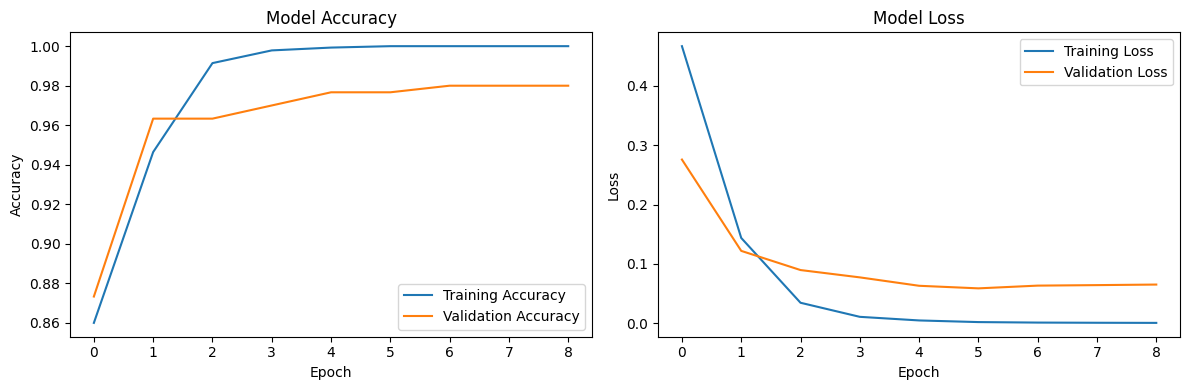

In [10]:

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


In [11]:

# Predict probabilities for test messages
y_prob = model.predict(X_test_pad, verbose=0).ravel()

# Convert probabilities to binary classes
y_pred = (y_prob >= 0.5).astype(int)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("GRU Model Evaluation")
print("------------------------")
print(f"Accuracy : {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall   : {recall * 100:.2f}%")
print(f"F1-Score : {f1 * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Ham", "Spam"],
    zero_division=0
))


GRU Model Evaluation
------------------------
Accuracy : 98.00%
Precision: 94.44%
Recall   : 89.47%
F1-Score : 91.89%

Classification Report:
              precision    recall  f1-score   support

         Ham       0.98      0.99      0.99       262
        Spam       0.94      0.89      0.92        38

    accuracy                           0.98       300
   macro avg       0.96      0.94      0.95       300
weighted avg       0.98      0.98      0.98       300



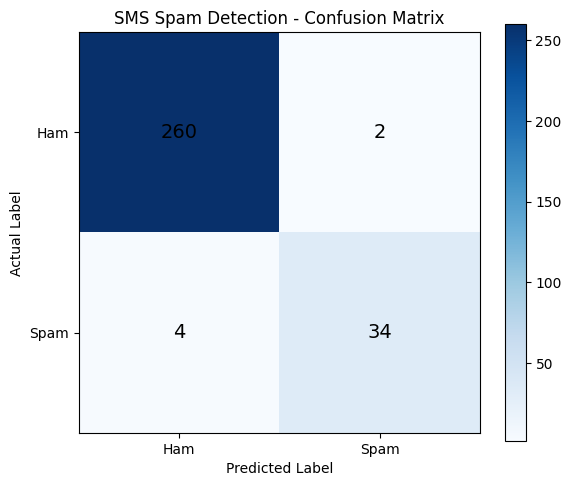

True Negatives : 260
False Positives: 2
False Negatives: 4
True Positives : 34


In [12]:

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues")
plt.title("SMS Spam Detection - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks([0, 1], ["Ham", "Spam"])
plt.yticks([0, 1], ["Ham", "Spam"])

for i in range(2):
    for j in range(2):
        plt.text(
            j, i, str(cm[i, j]),
            ha="center", va="center",
            fontsize=14
        )

plt.colorbar()
plt.tight_layout()
plt.show()

print("True Negatives :", cm[0, 0])
print("False Positives:", cm[0, 1])
print("False Negatives:", cm[1, 0])
print("True Positives :", cm[1, 1])


In [13]:

new_messages = [
    "Congratulations! You won a free cash prize. Claim now!",
    "Hi, are we meeting tomorrow at college?",
    "URGENT! Your bank account is blocked. Click to verify.",
    "Please send me the assignment notes.",
    "You have been selected for a free reward. Call now!"
]

cleaned_messages = [clean_text(msg) for msg in new_messages]

sequences = tokenizer.texts_to_sequences(cleaned_messages)

padded_messages = pad_sequences(
    sequences,
    maxlen=max_len,
    padding="post",
    truncating="post"
)

predictions = model.predict(padded_messages, verbose=0).ravel()

for msg, prob in zip(new_messages, predictions):
    result = "SPAM" if prob >= 0.5 else "HAM"

    print("\nMessage:", msg)
    print("Prediction:", result)
    print(f"Spam Probability: {prob * 100:.2f}%")



Message: Congratulations! You won a free cash prize. Claim now!
Prediction: SPAM
Spam Probability: 99.75%

Message: Hi, are we meeting tomorrow at college?
Prediction: HAM
Spam Probability: 0.00%

Message: URGENT! Your bank account is blocked. Click to verify.
Prediction: SPAM
Spam Probability: 94.27%

Message: Please send me the assignment notes.
Prediction: HAM
Spam Probability: 0.05%

Message: You have been selected for a free reward. Call now!
Prediction: SPAM
Spam Probability: 85.99%


In [15]:

sms = input("Enter an SMS message: ")

cleaned_sms = clean_text(sms)

sequence = tokenizer.texts_to_sequences([cleaned_sms])

padded_sms = pad_sequences(
    sequence,
    maxlen=max_len,
    padding="post",
    truncating="post"
)

probability = float(model.predict(padded_sms, verbose=0)[0][0])

print("\nSMS:", sms)

if probability >= 0.5:
    print("Prediction: SPAM")
else:
    print("Prediction: HAM")

print(f"Spam Probability: {probability * 100:.2f}%")


Enter an SMS message: I am reading a book

SMS: I am reading a book
Prediction: HAM
Spam Probability: 0.00%


In [16]:

import pickle

model.save("sms_spam_gru.keras")

with open("sms_tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)

print("Model and tokenizer saved successfully.")


Model and tokenizer saved successfully.
